In [5]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from collections import OrderedDict
from datasets import load_dataset
from sklearn.metrics import accuracy_score, classification_report

import experiment
import clslib
import analysis
import smlp
import loglin


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [6]:
dataset = load_dataset("stanfordnlp/sst2")
# temp_train_df = dataset["train"].to_pandas()
# temp_val_df = dataset["validation"].to_pandas()
# dataset_df = pd.concat([temp_train_df, temp_val_df], ignore_index=True).drop(columns=['idx'])
# train_df, val_df, test_df = np.split(dataset_df, [int(0.8 * len(dataset_df)), int(0.9 * len(dataset_df))])

# train_dataset = Dataset.from_pandas(train_df)
# val_dataset = Dataset.from_pandas(val_df)
# test_dataset = Dataset.from_pandas(test_df)
train_dataset = dataset["train"]
test_dataset = dataset["validation"]

In [7]:
vocab_size = 1000
min_frequency = 2
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []
results_folder = Path("./results")
results_folder.mkdir(exist_ok=True)

for seed in my_seeds:
    my_cross_validation_sets.append(
        experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(train_dataset["sentence"], train_dataset["label"])), 
            k=num_folds,
            seed=seed
        )
    )

bpe_tokenizer = experiment.train_bpe_tokenizer(train_dataset["sentence"], vocab_size, min_frequency)

bow_encoder = clslib.BagOfWords(bpe_tokenizer.get_vocab(), bpe_tokenizer)

my_classifiers = OrderedDict()

In [8]:
# test
text = "A good good movie"

print(bpe_tokenizer.encode(text).tokens)
print(len(bow_encoder))

['▁', '[UNK]', '▁good', '▁good', '▁movie']
1000


In [9]:
my_classifiers['logistic_bow-enc'] = []

for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_bow-enc/seed-{seed}"

    my_classifiers['logistic_bow-enc'].append(
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            encoder=bow_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\Alex\Documents\A Docs\Logic\Logic courses\NLP new\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\Alex\Documents\A Docs\Logic\Logic courses\NLP new\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\Alex\Documents\A Docs\Logic\Logic courses\NLP new\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\Alex\Documents\A Docs\Logic\Logic courses\NLP new\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWa

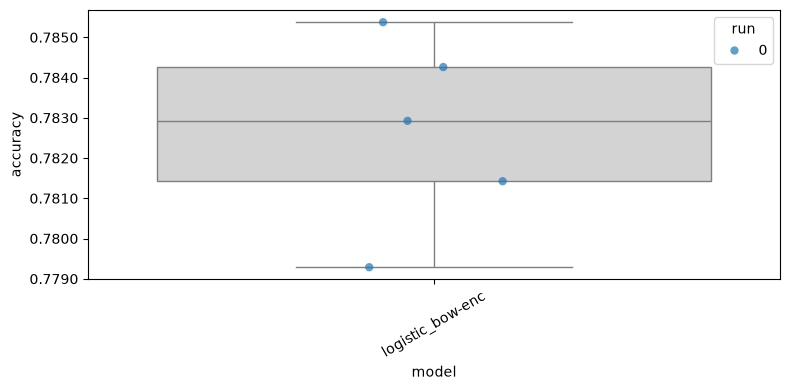

In [10]:
analysis.plot_box_and_points(analysis.make_data_frame(my_classifiers))

In [11]:
print(my_classifiers['logistic_bow-enc'][0]['accuracies'])

OrderedDict({0: 0.7853749072011879, 1: 0.7792873051224944, 2: 0.7829250185597625, 3: 0.7842613214550854, 4: 0.7814240106912169})


In [12]:
testing_sentences = test_dataset["sentence"]
testing_labels = test_dataset["label"]

for run, seed in enumerate(my_seeds):
    for fold in range(num_folds):
        model_path = f"{results_folder}/logistic_bow-enc/seed-{seed}/fold-{fold}/model"

        model = loglin.load(model_path)
        predictions = loglin.predict(
            testing_sentences, model, bow_encoder
        )

        print(f"Seed {seed}, fold {fold}:")
        print(f"Test accuracy: {accuracy_score(testing_labels, predictions):.4f}")

Seed 0, fold 0:
Test accuracy: 0.7546
Seed 0, fold 1:
Test accuracy: 0.7534
Seed 0, fold 2:
Test accuracy: 0.7580
Seed 0, fold 3:
Test accuracy: 0.7626
Seed 0, fold 4:
Test accuracy: 0.7557


In [13]:
# save results
Path("metrics").mkdir(exist_ok=True)

df = analysis.make_data_frame(my_classifiers)
df["seed"] = df["run"].map(dict(enumerate(my_seeds)))

df.to_csv(f"metrics/{next(iter(my_classifiers))}.csv", index=False)